## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [61]:
# Your Phase 1 solution to the problem goes here.


In [62]:
import numpy as np
import pandas as pd
import seaborn as sns

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

Text(0.5, 1.0, 'Noise=0.125')

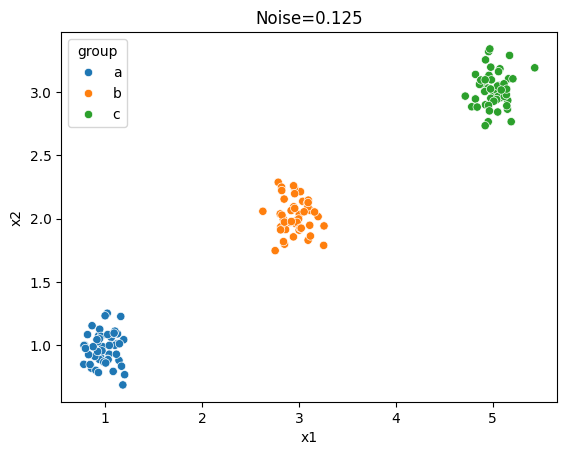

In [63]:
ax_0125 = sns.scatterplot(data=df0_125,x='x1',y='x2',hue='group')
ax_0125.set_title('Noise=0.125')


Text(0.5, 1.0, 'Noise=0.25')

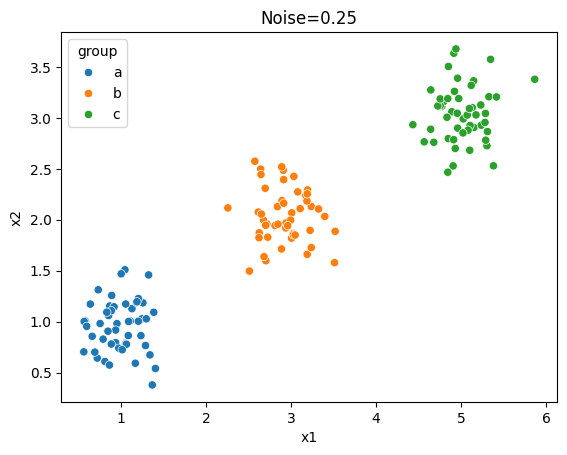

In [64]:
ax_025 = sns.scatterplot(data=df0_25,x='x1',y='x2',hue='group')
ax_025.set_title('Noise=0.25')

Text(0.5, 1.0, 'Noise=0.5')

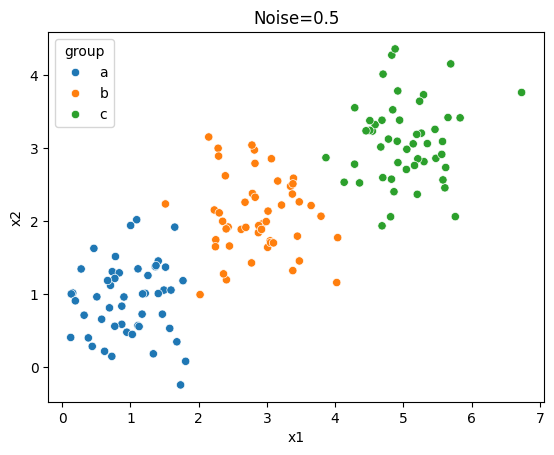

In [65]:
ax_05 = sns.scatterplot(data=df0_5,x='x1',y='x2',hue='group')
ax_05.set_title('Noise=0.5')

Text(0.5, 1.0, 'Noise=1')

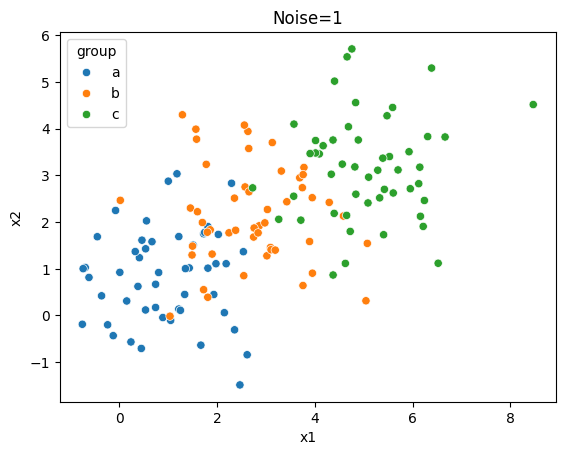

In [66]:
ax_1 = sns.scatterplot(data=df1_0,x='x1',y='x2',hue='group')
ax_1.set_title('Noise=1')

The clusters are less distinct as noise increases

Text(0.5, 1.0, 'Noise=2')

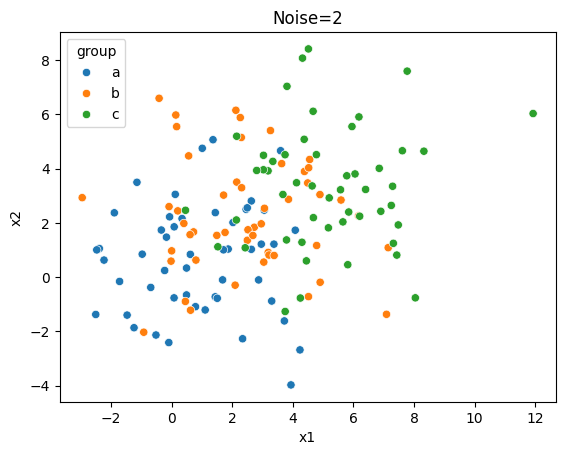

In [67]:
ax_2 = sns.scatterplot(data=df2_0,x='x1',y='x2',hue='group')
ax_2.set_title('Noise=2')

In [68]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

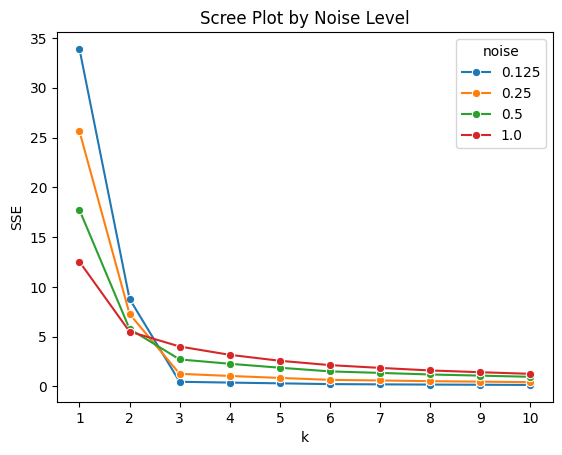

In [69]:
datasets = {"0.125": df0_125, "0.25": df0_25, "0.5": df0_5, "1.0": df1_0}
ks = np.arange(1, 11)

rows = []
for noise, df in datasets.items():
    features = df[["x1", "x2"]]
    mins = features.min()
    ranges = features.max() - mins
    X = (features - mins) / ranges
    for k in ks:
        sse = KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_
        rows.append({"k": k, "SSE": sse, "noise": noise})

scree = pd.DataFrame(rows)

ax = sns.lineplot(data=scree, x="k", y="SSE", hue="noise", marker="o")
ax.set(title="Scree Plot by Noise Level", xlabel="k", ylabel="SSE", xticks=ks)
plt.show()

As noise increases, it becomes more difficult to see a clear elbow which makes it hard to select a k value

4.

In [70]:
from google.colab import drive
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/DS3001/SIPRIMilitaryExpenditureDatabase.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [71]:
df2020 = df[df["Year"] == 2020].dropna()

In [72]:
df2020.describe()

,index,Year,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
count,148.000000,148.0,148.000000,148.000000,148.000000,148.000000
mean,2831.256757,2020.0,13153.747670,0.019619,0.061510,268.264494
std,1654.299355,0.0,68005.236120,0.015033,0.046207,430.434878
min,32.000000,2020.0,8.622460,0.000054,0.004896,0.580129
25%,1409.000000,2020.0,204.877177,0.010413,0.031352,20.553464
50%,2871.000000,2020.0,959.535443,0.015324,0.047402,81.506703
75%,4222.500000,2020.0,5289.998320,0.024327,0.084681,326.267753
max,5880.000000,2020.0,778397.200000,0.098470,0.303027,2520.398541


In [73]:
df2020= df2020.drop(columns ='index')

In [74]:
features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = df2020.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

,Spending (2020 USD),Spending per Capita
min,0.0,0.0
max,1.0,1.0


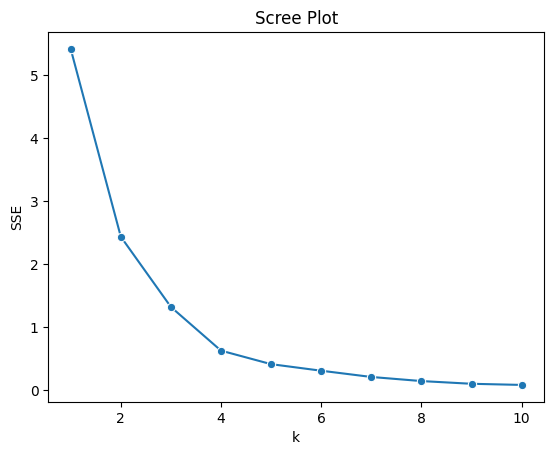

In [75]:
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, marker="o").set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

In [76]:
model = KMeans(n_clusters=4, max_iter=300, n_init=10, random_state=0).fit(X)
df2020["cluster"] = model.labels_
centers = model.cluster_centers_ * ranges.to_numpy() + mins.to_numpy()

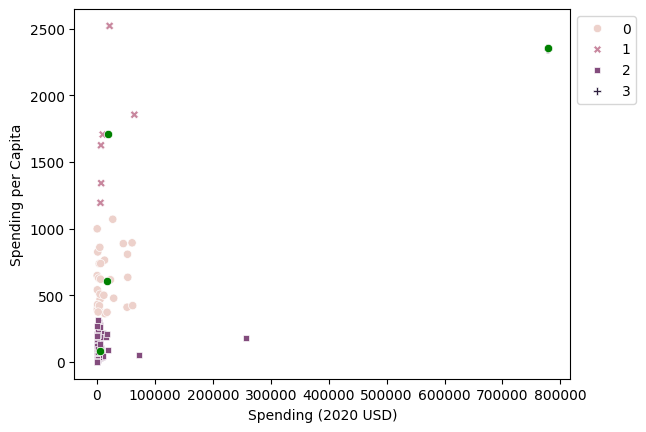

In [77]:
ax = sns.scatterplot(
    data=df2020, x="Spending (2020 USD)", y="Spending per Capita",
    hue="cluster", style="cluster"
)
sns.scatterplot(x=centers[:, 0], y=centers[:, 1], color="green", ax=ax)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()

In [78]:
df2020.groupby("cluster")[features].describe()

Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      30.0   17077.591354  20583.053357     405.790494   
1                       6.0   19443.362047  22861.507114    6095.708713   
2                     111.0    4859.185065  25405.739131       8.622460   
3                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          2294.039665    5857.060906   26296.001003   61712.537169   
1          7023.251766    8624.225729   18857.070183   64558.400000   
2           130.010211     382.464677    2297.032353  257973.429834   
3        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                      30.0   607.478618  206.928757   362.467076   
1                       6.0  1706.721916  466.375705  1193.598730   
2                     111.0    80.061470   83.501824     0.580129   
3                       1.0  2351.631858         NaN  2351.631858   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0         422.208252   579.004604   757.328513  1070.623322  
1        1412.083201  1665.447478  1817.219993  2520.398541  
2          14.880549    47.056944   125.387558   314.201312  
3        2351.631858  2351.631858  2351.631858  2351.631858

In [80]:
for c in sorted(df2020["cluster"].unique()):
    print(c, sorted(df2020.loc[df2020["cluster"] == c, "Country"]))

0 ['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brunei', 'Canada', 'Cyprus', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Italy', 'Japan', 'Korea, South', 'Latvia', 'Lithuania', 'Luxembourg', 'Netherlands', 'New Zealand', 'Poland', 'Portugal', 'Russia', 'Slovakia', 'Spain', 'Sweden', 'Switzerland', 'Taiwan', 'United Kingdom']
1 ['Israel', 'Kuwait', 'Norway', 'Oman', 'Saudi Arabia', 'Singapore']
2 ['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina', 'Armenia', 'Azerbaijan', 'Bangladesh', 'Belarus', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Cape Verde', 'Central African Republic', 'Chad', 'Chile', 'China', 'Colombia', 'Congo, DR', 'Congo, Republic', 'Croatia', 'Czechia', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Ethiopia', 'Fiji', 'Gabon', 'Gambia, The', 'Georgia', 'Ghana', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana', 

The U.S. is in a cluster by itself, far outweighing other countries spending. There are also patterns in clusters, with cluster 1 being oil rich or otherwise very wealthy countries, and cluster 0 having a lot of mid-economy democracies and U.S. allies.

In [81]:
features2 = ["Percent of Government Spending", "Percent of GDP"]
unscaled2 = df2020.loc[:, features2]
mins2 = unscaled2.min()
ranges2 = unscaled2.max() - mins2
X2 = (unscaled2 - mins2) / ranges2
X2.agg(["min", "max"])

,Percent of Government Spending,Percent of GDP
min,0.0,0.0
max,1.0,1.0


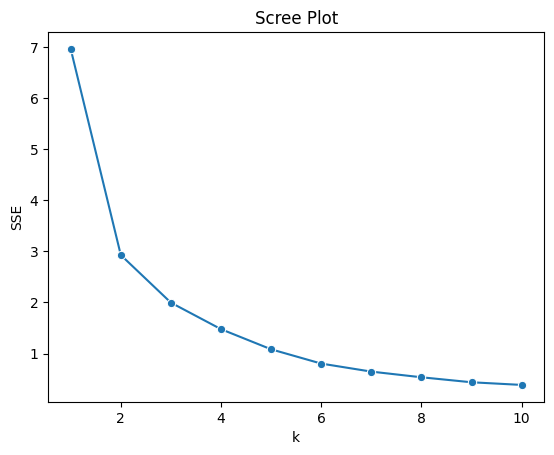

In [82]:
ks = np.arange(1, 11)
SSE2 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X2).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE2, marker="o").set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

In [83]:
model2 = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0).fit(X2)
df2020["cluster2"] = model2.labels_
centers2 = model2.cluster_centers_ * ranges2.to_numpy() + mins2.to_numpy()

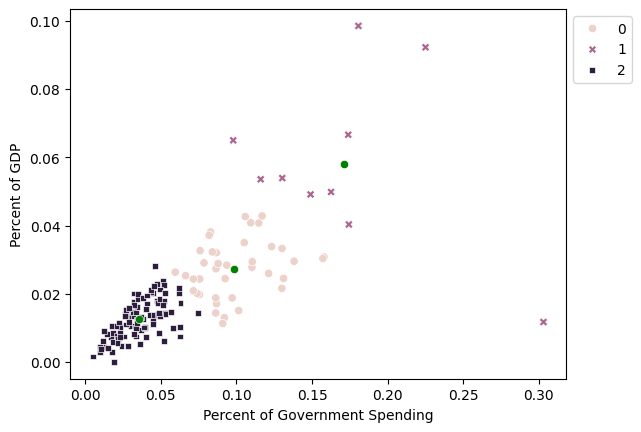

In [84]:
ax = sns.scatterplot(
    data=df2020, x="Percent of Government Spending", y="Percent of GDP",
    hue="cluster2", style="cluster2"
)
sns.scatterplot(x=centers2[:, 0], y=centers2[:, 1], color="green", ax=ax)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()

In [85]:
df2020.groupby("cluster2")[features2].describe()

for c in sorted(df2020["cluster2"].unique()):
    print(c, sorted(df2020.loc[df2020["cluster2"] == c, "Country"]))

0 ['Bahrain', 'Bangladesh', 'Botswana', 'Brunei', 'Burkina Faso', 'Burundi', 'Cambodia', 'Central African Republic', 'Chad', 'Chile', 'Colombia', 'Congo, Republic', 'Ecuador', 'Equatorial Guinea', 'Gabon', 'Guinea', 'India', 'Iran', 'Iraq', 'Korea, South', 'Lebanon', 'Mali', 'Mauritania', 'Morocco', 'Myanmar', 'Namibia', 'Niger', 'Russia', 'Singapore', 'South Sudan', 'Sri Lanka', 'Sudan', 'Taiwan', 'Togo', 'Tunisia', 'Turkey', 'Uganda', 'Ukraine', 'United States of America']
1 ['Algeria', 'Armenia', 'Azerbaijan', 'Belarus', 'Israel', 'Jordan', 'Kuwait', 'Oman', 'Pakistan', 'Saudi Arabia']
2 ['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Australia', 'Austria', 'Belgium', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Cameroon', 'Canada', 'Cape Verde', 'China', 'Congo, DR', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic', 'Egypt', 'El Salvador', 'Estonia', 'Ethiopia', 'Fiji', 'Finland', 'France', 'Gambia, The', 'Georgia', 'Germany', 'Gh

Clustering by percent of gdp being used for military is much clearer to compare how each country prioritizes the military, while clustering by spending per capita just had us see which countries were bigger and spent more.

In [86]:
features3 = ["Spending (2020 USD)", "Spending per Capita",
             "Percent of Government Spending", "Percent of GDP"]
unscaled3 = df2020.loc[:, features3]
mins3 = unscaled3.min()
ranges3 = unscaled3.max() - mins3
X3 = (unscaled3 - mins3) / ranges3

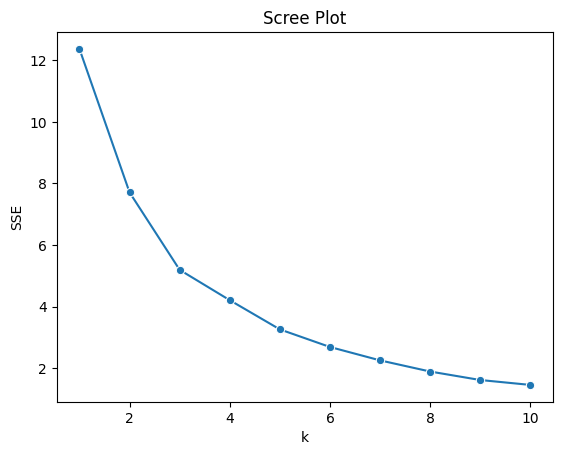

In [87]:
ks = np.arange(1, 11)
SSE3 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X3).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE3, marker="o").set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

In [88]:
model3 = KMeans(n_clusters=4, max_iter=300, n_init=10, random_state=0).fit(X3)
df2020["cluster3"] = model3.labels_

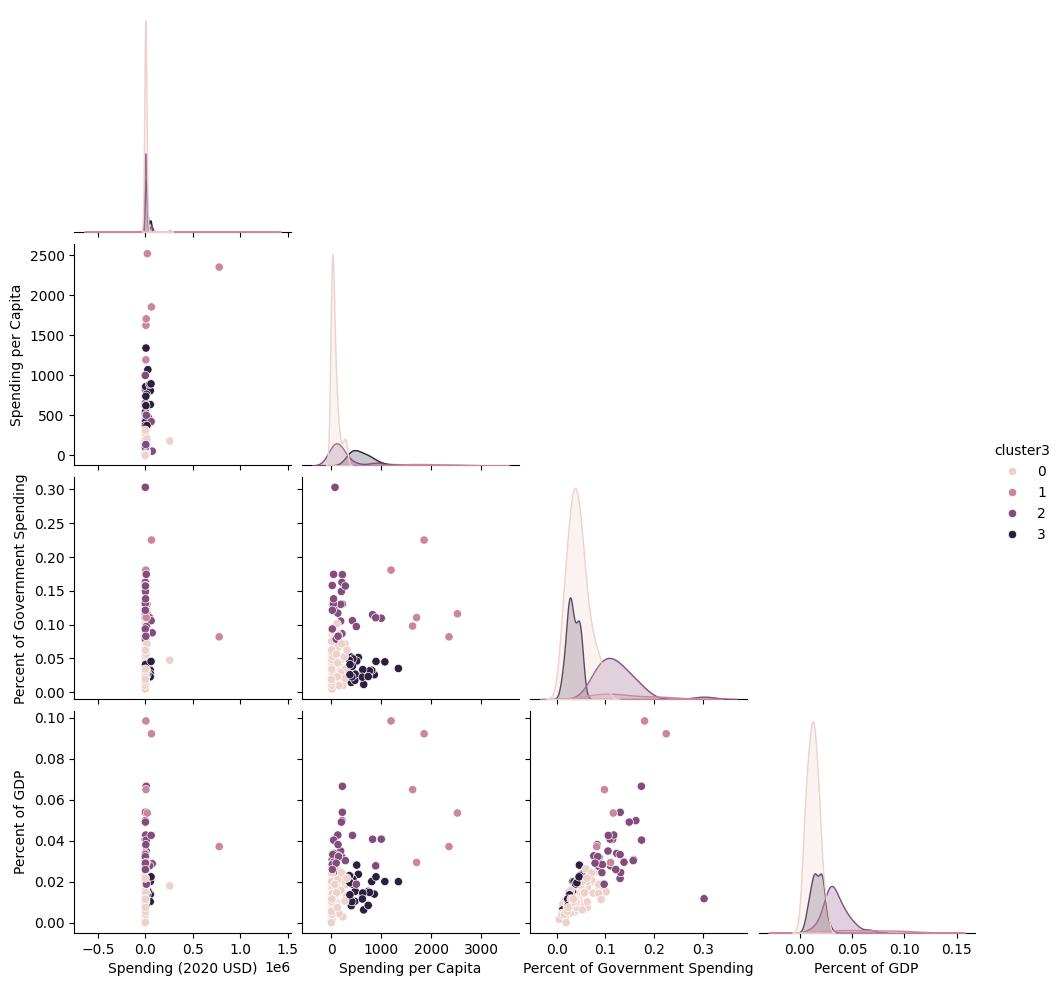

In [89]:
sns.pairplot(df2020, vars=features3, hue="cluster3", corner=True)
plt.show()

In [90]:
df2020.groupby("cluster3")[features3].describe()

for c in sorted(df2020["cluster3"].unique()):
    print(c, sorted(df2020.loc[df2020["cluster3"] == c, "Country"]))

0 ['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Bangladesh', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Burundi', 'Cameroon', 'Cape Verde', 'Central African Republic', 'Chile', 'China', 'Congo, DR', 'Croatia', 'Czechia', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Ethiopia', 'Fiji', 'Gabon', 'Gambia, The', 'Georgia', 'Ghana', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana', 'Haiti', 'Honduras', 'Hungary', 'Indonesia', 'Ireland', 'Jamaica', 'Kazakhstan', 'Kenya', 'Kosovo', 'Kyrgyz Republic', 'Lesotho', 'Liberia', 'Madagascar', 'Malawi', 'Malaysia', 'Malta', 'Mauritius', 'Mexico', 'Moldova', 'Mongolia', 'Montenegro', 'Mozambique', 'Nepal', 'Nicaragua', 'Niger', 'Nigeria', 'North Macedonia', 'Papua New Guinea', 'Paraguay', 'Peru', 'Philippines', 'Romania', 'Rwanda', 'Senegal', 'Serbia', 'Seychelles', 'Sierra Leone', 'Slovenia', 'South Africa', 'South Sudan', 'Sri Lanka', 'Sudan', 'Tajikistan', 'Tanzania', 'Thaila

The first clustering separated countries by wealth (per capita spending) and the second by burden (share of GDP and budget). Using all four variables splits on both at once, giving wealthy vs. not, and high-burden vs. low-burden. That’s why the four groups are easier to interpret than either earlier clustering.

5. Yes, there were useful patterns found with the k-MC algorithm, but it's clear that choosing features/measures of spending can change how we see the data and tell the story. The most useful was the third feature, where we have a good middleground with the data taking into account all the variables.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]